# Welch ASD with GWexpy and spicypy

This example transfers a GWexpy time series through the shared GWpy interface and calculates an amplitude spectral density (ASD) with spicypy. It uses synthetic data and requires separately installed `spicypy`; it does not need a spicypy adapter. The comparison checks the transfer, not the statistical correctness of Welch's estimator.

Install spicypy separately in an environment compatible with GWexpy. The example was verified with spicypy 1.2 and GWpy 4.0.2.

In [1]:
import numpy as np
from astropy import units as u
from gwexpy.timeseries import TimeSeries
from spicypy.signal import TimeSeries as SpiceTimeSeries

# Construct a reproducible signal with a known time origin and physical unit.
sample_rate = 128
time = np.arange(1024) / sample_rate
data = np.sin(2 * np.pi * 12 * time) + 0.1 * np.cos(2 * np.pi * 20 * time)
source = TimeSeries(data, sample_rate=sample_rate, t0=1234567890, unit="m", name="signal")
converted = SpiceTimeSeries.from_other(source)
direct = SpiceTimeSeries(data, sample_rate=sample_rate, t0=1234567890, unit="m", name="signal")

Check the values and time metadata before analysis. Both paths receive the same data; the second is a direct spicypy construction used as a reference.

In [2]:
np.testing.assert_array_equal(converted.value, direct.value)
np.testing.assert_array_equal(converted.times.value, direct.times.value)
assert converted.unit == direct.unit == u.m
assert converted.name == direct.name == "signal"
assert converted.t0 == direct.t0 and converted.dt == direct.dt

asd = converted.asd(fftlength=2, method="welch")
reference = direct.asd(fftlength=2, method="welch")
np.testing.assert_allclose(asd.value, reference.value, rtol=1e-12, atol=0)
np.testing.assert_array_equal(asd.frequencies.value, reference.frequencies.value)
assert asd.unit == reference.unit == u.m / u.Hz**0.5
print("Values, axes, units and input metadata agree.")

# A 12 Hz sinusoid should dominate, and integrated one-sided PSD should
# reproduce the mean-square value of this stationary synthetic signal.
assert asd.frequencies.value[np.argmax(asd.value)] == 12
power = np.trapezoid(asd.value**2, asd.frequencies.value)
np.testing.assert_allclose(power, np.mean(data**2), rtol=0.02)
print(f"Peak: 12 Hz; integrated PSD: {power:.5f} m^2")

Values, axes, units and input metadata agree.
Peak: 12 Hz; integrated PSD: 0.50500 m^2


The ASD uses Welch averaging over two-second segments. Its frequency spacing is 0.5 Hz; its squared units are power per Hz. The result is an ASD, not a calibration of the synthetic signal.

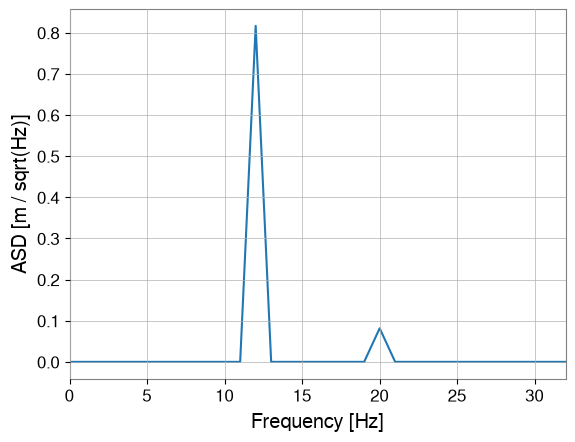

In [3]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots()
ax.plot(asd.frequencies.value, asd.value)
ax.set(xlim=(0, 32), xlabel="Frequency [Hz]", ylabel="ASD [m / sqrt(Hz)]")
ax.grid(True)
plt.show()